# Reconocimiento de actividades humanas mediante TinyML

## 1. Exploración del dataset UCI HAR

El objetivo de este proyecto es implementar un modelo de aprendizaje automático
en un ESP32 simulado mediante Wokwi, capaz de identificar seis actividades humanas
a partir de señales inerciales.

Se utilizará el dataset **Human Activity Recognition Using Smartphones**,
disponible en UCI Machine Learning Repository.

Las actividades consideradas son:

1. WALKING
2. WALKING_UPSTAIRS
3. WALKING_DOWNSTAIRS
4. SITTING
5. STANDING
6. LAYING

Cada ventana contiene 128 muestras registradas a 50 Hz, utilizando seis señales:
tres de aceleración y tres de velocidad angular.

El análisis comprende la exploración de los datos, verificación de dimensiones,
distribución de clases y visualización de señales representativas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)

In [2]:
# Ubicación del dataset

rutas_base = [Path.cwd(), *list(Path.cwd().parents)[:3]]

candidatos = [
    base / subruta
    for base in rutas_base
    for subruta in [
        "humanActivityRecognitionUsingSmartPhones/UCI HAR Dataset",
        "UCI HAR Dataset"
    ]
]

DATASET = next(
    (ruta.resolve() for ruta in candidatos
     if (ruta / "activity_labels.txt").is_file()),
    None
)

if DATASET is None:
    raise FileNotFoundError(
        f"No se encontró el dataset desde {Path.cwd()}"
    )

print("Dataset encontrado en:")
print(DATASET)

Dataset encontrado en:
/Users/jrgels/Documents/Maestria/TERCER SEMESTRE/TinyML/Proyecto 1/humanActivityRecognitionUsingSmartPhones/UCI HAR Dataset


In [ ]:
# Cargar las señales inerciales

CANALES = [
    "total_acc_x",
    "total_acc_y",
    "total_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z"
]

def cargar_datos(split):
    carpeta = DATASET / split
    señales = carpeta / "Inertial Signals"

    X = np.stack([
        np.loadtxt(
            señales / f"{canal}_{split}.txt",
            dtype=np.float32
        )
        for canal in CANALES
    ], axis=-1)

    y = np.loadtxt(
        carpeta / f"y_{split}.txt",
        dtype=np.int64
    )

    sujetos = np.loadtxt(
        carpeta / f"subject_{split}.txt",
        dtype=np.int64
    )

    return X, y, sujetos


X_train, y_train, sujetos_train = cargar_datos("train")
X_test, y_test, sujetos_test = cargar_datos("test")

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)

print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (7352, 128, 6)
X_test:  (2947, 128, 6)
y_train: (7352,)
y_test:  (2947,)


In [4]:
# Distribucion de actividades

etiquetas = pd.read_csv(
    DATASET / "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["id", "actividad"]
)

distribucion = pd.DataFrame({
    "Entrenamiento": pd.Series(y_train).value_counts(),
    "Prueba": pd.Series(y_test).value_counts()
}).fillna(0).astype(int)

distribucion["Total"] = (
    distribucion["Entrenamiento"] +
    distribucion["Prueba"]
)

distribucion.index = [
    etiquetas.set_index("id").loc[i, "actividad"]
    for i in distribucion.index
]

display(distribucion)

# Comprobar separación por sujetos
compartidos = np.intersect1d(sujetos_train, sujetos_test)

print("Sujetos compartidos:", compartidos)

,Entrenamiento,Prueba,Total
WALKING,1226,496,1722
WALKING_UPSTAIRS,1073,471,1544
WALKING_DOWNSTAIRS,986,420,1406
SITTING,1286,491,1777
STANDING,1374,532,1906
LAYING,1407,537,1944


Sujetos compartidos: []


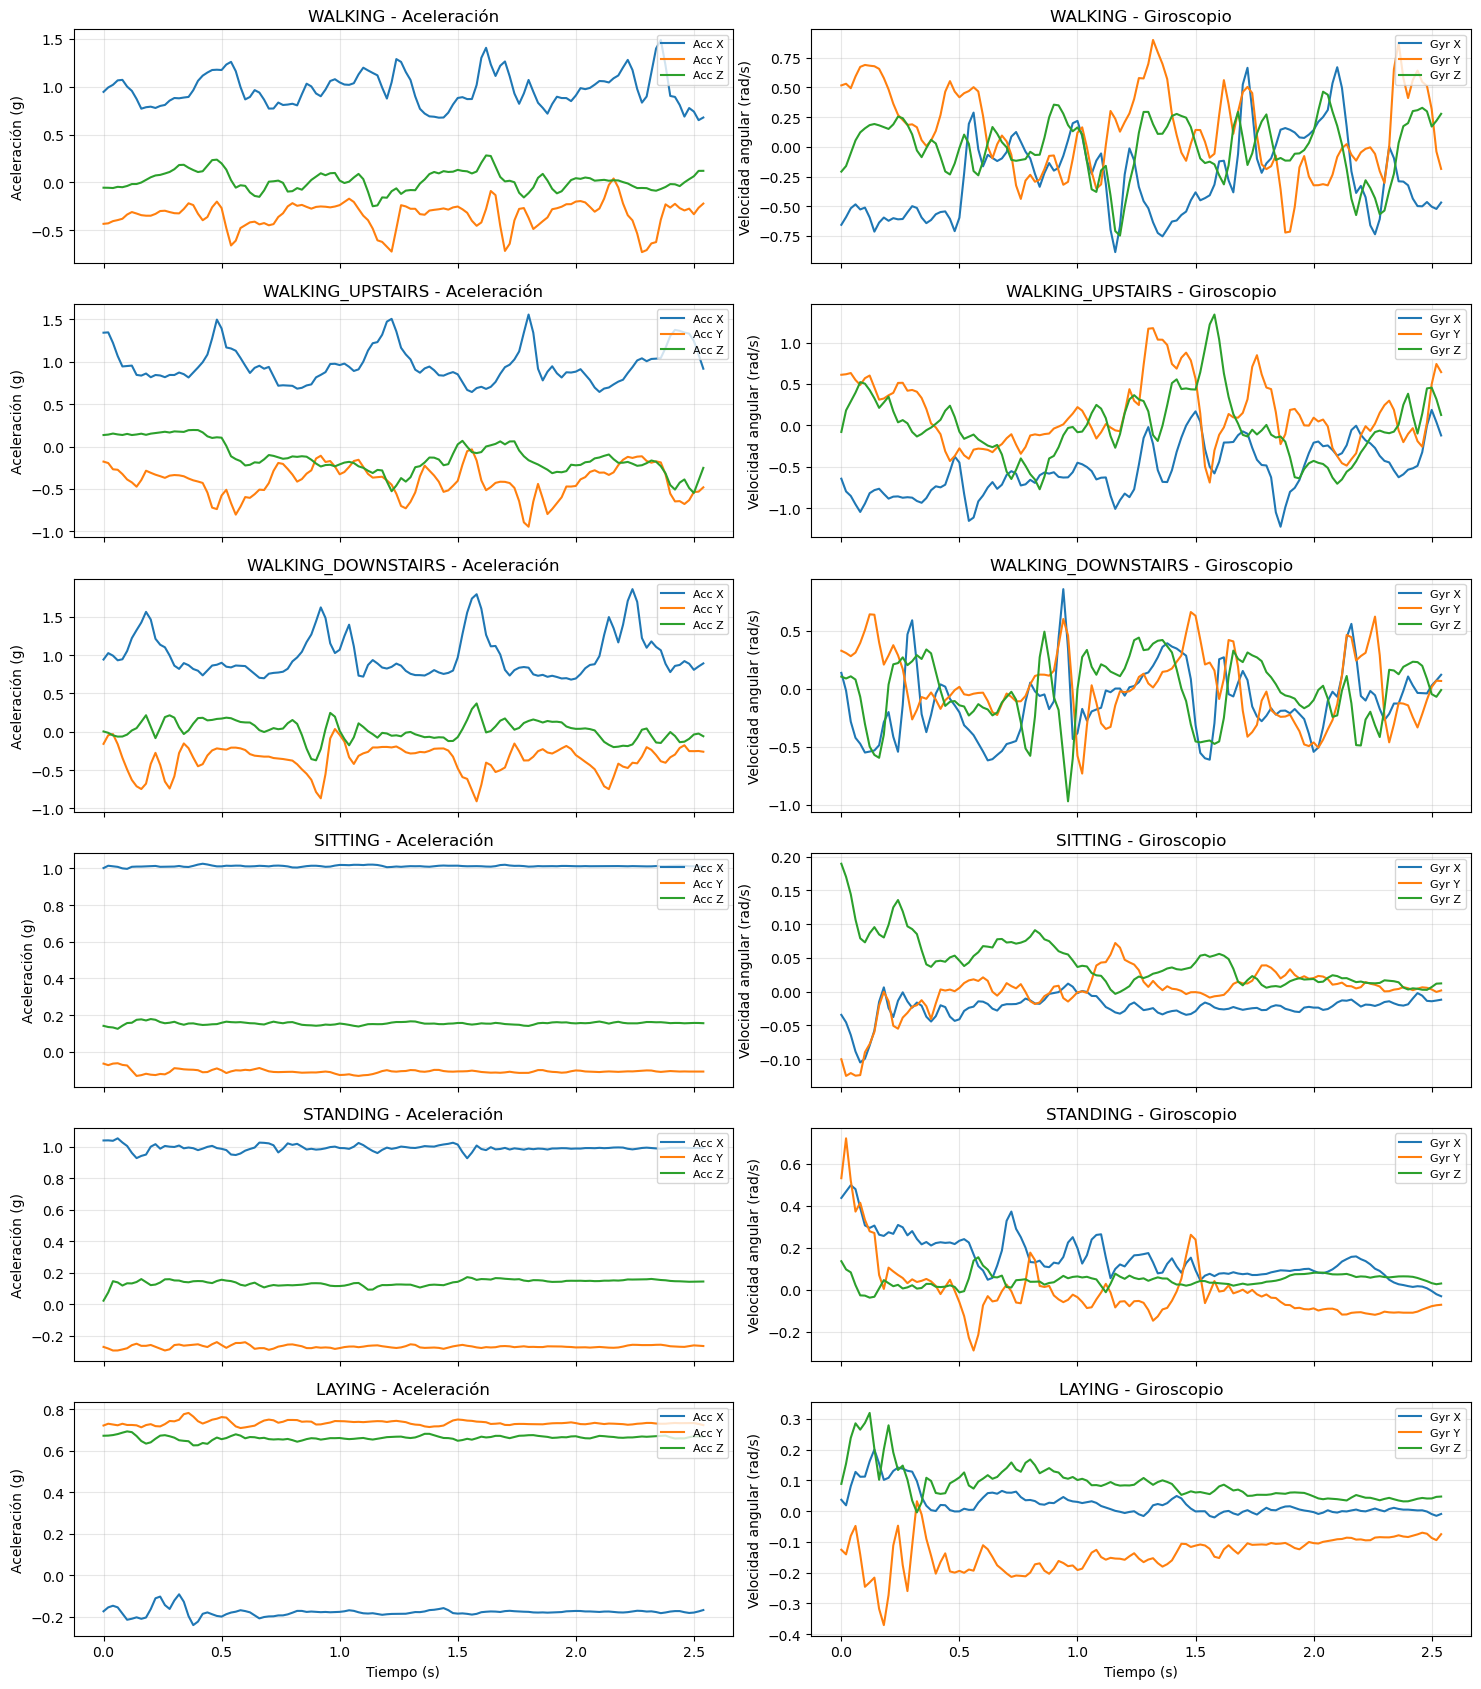

In [5]:
# Visualizacion de señales por actividad

frecuencia = 50
tiempo = np.arange(128) / frecuencia

fig, axes = plt.subplots(
    6, 2,
    figsize=(15, 17),
    sharex=True
)

for fila, (id_actividad, nombre) in enumerate(
    etiquetas.itertuples(index=False, name=None)
):
    indice = np.flatnonzero(y_test == id_actividad)[0]
    ventana = X_test[indice]

    # Aceleración
    for eje, nombre_eje in enumerate(["X", "Y", "Z"]):
        axes[fila, 0].plot(
            tiempo,
            ventana[:, eje],
            label=f"Acc {nombre_eje}"
        )

    # Velocidad angular
    for eje, nombre_eje in enumerate(["X", "Y", "Z"]):
        axes[fila, 1].plot(
            tiempo,
            ventana[:, eje + 3],
            label=f"Gyr {nombre_eje}"
        )

    axes[fila, 0].set_title(f"{nombre} - Aceleración")
    axes[fila, 1].set_title(f"{nombre} - Giroscopio")

    axes[fila, 0].set_ylabel("Aceleración (g)")
    axes[fila, 1].set_ylabel("Velocidad angular (rad/s)")

    for ax in axes[fila]:
        ax.grid(alpha=0.3)
        ax.legend(loc="upper right", fontsize=8)

axes[-1, 0].set_xlabel("Tiempo (s)")
axes[-1, 1].set_xlabel("Tiempo (s)")

plt.tight_layout()
plt.show()

# 2. Extraccion de caracteristicas

| Característica      | Descripción               |
| ------------------- | ------------------------- |
| Media               | Valor promedio            |
| Desviación estándar | Variabilidad de la señal  |
| Mínimo              | Valor más bajo            |
| Máximo              | Valor más alto            |
| RMS                 | Magnitud cuadrática media |

In [6]:
# Características estadísticas por canal
ESTADISTICAS = ["mean", "std", "min", "max", "rms"]

def extraer_caracteristicas(X):
    """
    X: (n_ventanas, 128, 6)

    Retorna:
        Matriz de características (n_ventanas, 30)
    """

    media = np.mean(X, axis=1)
    desviacion = np.std(X, axis=1)
    minimo = np.min(X, axis=1)
    maximo = np.max(X, axis=1)
    rms = np.sqrt(np.mean(X**2, axis=1))

    return np.concatenate(
        [media, desviacion, minimo, maximo, rms],
        axis=1
    )


# Extraer características
X_train_features = extraer_caracteristicas(X_train)
X_test_features = extraer_caracteristicas(X_test)

# Nombres de las 30 características
nombres_features = [
    f"{estadistica}_{canal}"
    for estadistica in ESTADISTICAS
    for canal in CANALES
]

print("Entrenamiento:", X_train_features.shape)
print("Prueba:", X_test_features.shape)

assert len(nombres_features) == 30
assert np.isfinite(X_train_features).all()
assert np.isfinite(X_test_features).all()


Entrenamiento: (7352, 30)
Prueba: (2947, 30)


In [ ]:
# Inspeccion de caracteristicas

df_features = pd.DataFrame(
    X_train_features,
    columns=nombres_features
)

df_features["Actividad"] = [
    etiquetas.set_index("id").loc[i, "actividad"]
    for i in y_train
]

display(df_features.head())

# Resumen estadístico
display(df_features.describe())

,mean_total_acc_x,mean_total_acc_y,mean_total_acc_z,mean_body_gyro_x,mean_body_gyro_y,mean_body_gyro_z,std_total_acc_x,std_total_acc_y,std_total_acc_z,std_body_gyro_x,std_body_gyro_y,std_body_gyro_z,min_total_acc_x,min_total_acc_y,min_total_acc_z,min_body_gyro_x,min_body_gyro_y,min_body_gyro_z,max_total_acc_x,max_total_acc_y,max_total_acc_z,max_body_gyro_x,max_body_gyro_y,max_body_gyro_z,rms_total_acc_x,rms_total_acc_y,rms_total_acc_z,rms_body_gyro_x,rms_body_gyro_y,rms_body_gyro_z,Actividad
0,1.019304,-0.124262,0.099732,0.022250,0.019403,0.009468,0.001791,0.003270,0.003970,0.014434,0.019828,0.005943,1.012817,-0.132631,0.088742,-0.003862,-0.009022,-0.006891,1.024606,-0.117210,0.109485,0.050545,0.074850,0.022859,1.019306,0.124305,0.099811,0.026522,0.027742,0.011179,STANDING
1,1.019448,-0.122936,0.096939,0.011926,-0.004314,0.006308,0.001932,0.004930,0.004918,0.016334,0.010356,0.007431,1.012893,-0.132631,0.081100,-0.038650,-0.030160,-0.009759,1.024606,-0.108560,0.105788,0.055249,0.016858,0.025133,1.019450,0.123034,0.097064,0.020224,0.011219,0.009747,STANDING
2,1.019926,-0.124997,0.092897,-0.004150,-0.012640,0.004335,0.002904,0.006460,0.006145,0.022256,0.006920,0.008753,1.009013,-0.137142,0.081100,-0.038650,-0.037503,-0.009759,1.027664,-0.108560,0.105788,0.055249,0.000761,0.028609,1.019931,0.125164,0.093100,0.022640,0.014410,0.009768,STANDING
3,1.020349,-0.130493,0.087654,-0.016228,-0.007697,-0.000352,0.002574,0.004029,0.004945,0.009165,0.007793,0.008186,1.009013,-0.143545,0.076888,-0.037516,-0.037503,-0.013223,1.027664,-0.116749,0.098737,0.010361,0.007778,0.028609,1.020352,0.130555,0.087793,0.018638,0.010953,0.008194,STANDING
4,1.020255,-0.130209,0.084999,-0.006483,-0.000166,-0.003957,0.001949,0.003876,0.003637,0.014544,0.007815,0.008260,1.013645,-0.143545,0.074595,-0.024902,-0.020582,-0.021141,1.026194,-0.121456,0.093388,0.043706,0.017447,0.019890,1.020257,0.130267,0.085077,0.015923,0.007817,0.009159,STANDING


,mean_total_acc_x,mean_total_acc_y,mean_total_acc_z,mean_body_gyro_x,mean_body_gyro_y,mean_body_gyro_z,std_total_acc_x,std_total_acc_y,std_total_acc_z,std_body_gyro_x,std_body_gyro_y,std_body_gyro_z,min_total_acc_x,min_total_acc_y,min_total_acc_z,min_body_gyro_x,min_body_gyro_y,min_body_gyro_z,max_total_acc_x,max_total_acc_y,max_total_acc_z,max_body_gyro_x,max_body_gyro_y,max_body_gyro_z,rms_total_acc_x,rms_total_acc_y,rms_total_acc_z,rms_body_gyro_x,rms_body_gyro_y,rms_body_gyro_z
count,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000
mean,0.804749,0.028755,0.086498,0.000506,-0.000824,0.000113,0.127444,0.082753,0.070886,0.243794,0.249152,0.168811,0.585812,-0.215919,-0.103294,-0.549242,-0.578488,-0.412911,1.124611,0.196441,0.245178,0.543604,0.662617,0.373870,0.834951,0.319868,0.285424,0.279004,0.255803,0.177849
std,0.366131,0.372431,0.342719,0.187867,0.059768,0.061655,0.145657,0.085700,0.074392,0.266052,0.283152,0.181965,0.350926,0.562020,0.488384,0.653148,0.678327,0.464741,0.608197,0.319585,0.306718,0.622313,0.812211,0.408455,0.349262,0.226706,0.232424,0.296086,0.283530,0.183791
min,-0.370700,-0.494512,-0.988372,-0.914161,-0.351097,-0.437807,0.001340,0.001510,0.002969,0.001692,0.002003,0.002184,-0.466556,-1.582079,-1.639609,-4.733656,-5.974330,-2.763014,-0.314170,-0.444567,-0.978027,-0.241776,-0.113510,-0.239766,0.002962,0.003017,0.003700,0.001965,0.002026,0.002200
25%,0.902589,-0.220897,-0.127711,-0.016216,-0.013213,-0.009825,0.003414,0.004724,0.005770,0.012037,0.014576,0.008548,0.355264,-0.679154,-0.400259,-0.986721,-0.995558,-0.780125,0.960782,-0.012442,0.042551,0.025162,0.032473,0.018764,0.918277,0.174738,0.125216,0.013798,0.016306,0.010545
50%,0.983997,-0.124932,0.019812,-0.000002,-0.000198,-0.000097,0.013844,0.019710,0.020322,0.078450,0.064882,0.055189,0.583927,-0.257903,-0.116149,-0.181728,-0.188648,-0.130487,1.035682,0.120476,0.213361,0.188552,0.185343,0.146145,1.004153,0.263969,0.202054,0.112584,0.088605,0.089364
75%,1.011098,0.167153,0.223316,0.017685,0.010035,0.010297,0.245544,0.164297,0.131835,0.454575,0.436557,0.324051,0.961749,0.124988,0.182312,-0.025295,-0.034147,-0.017546,1.607996,0.335699,0.420355,1.012425,1.135222,0.681101,1.025339,0.385737,0.374049,0.521207,0.442615,0.329948
max,1.055334,1.005326,0.977294,0.790661,0.485058,0.404380,0.648704,0.369380,0.356817,1.736491,1.527045,0.966791,1.022497,0.993726,0.965509,0.387086,0.256098,0.247760,2.197618,1.217350,1.281363,4.155473,5.746062,2.365982,1.148428,1.005337,0.988379,1.821499,1.539875,1.007686


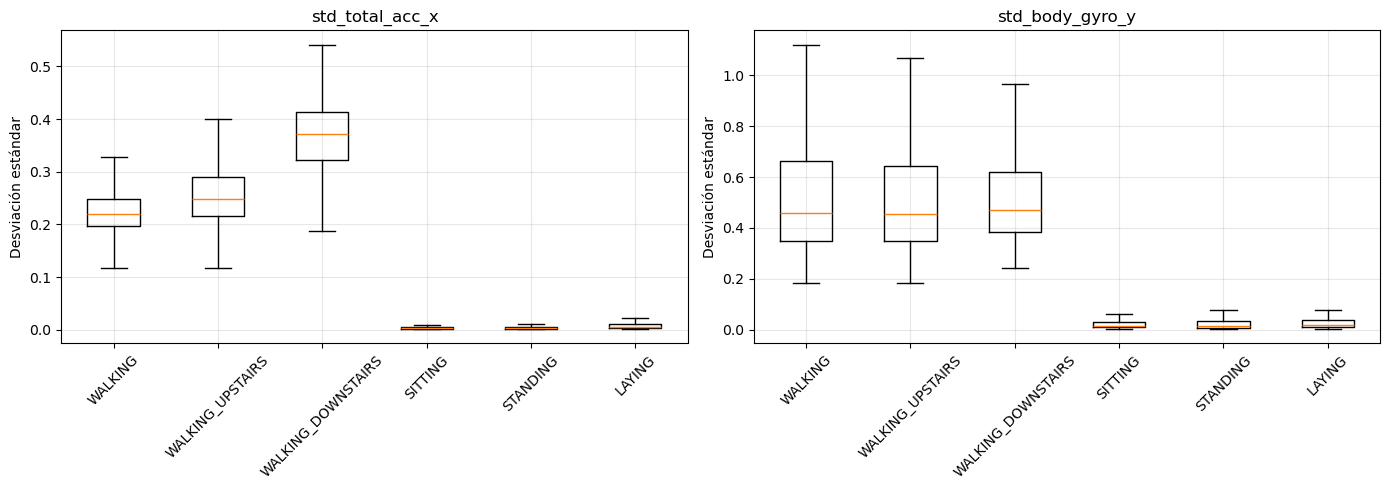

In [8]:
# Comparacion de la variabilidad por actividad

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

features_comparar = [
    "std_total_acc_x",
    "std_body_gyro_y"
]

for ax, feature in zip(axes, features_comparar):

    datos = [
        df_features.loc[
            df_features["Actividad"] == actividad,
            feature
        ].values
        for actividad in etiquetas["actividad"]
    ]

    ax.boxplot(
        datos,
        tick_labels=etiquetas["actividad"],
        showfliers=False
    )

    ax.set_title(feature)
    ax.set_ylabel("Desviación estándar")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
# Relación entre ventanas, sujetos y actividades
mapa_actividades = etiquetas.set_index("id")["actividad"]

df_ventanas = pd.DataFrame({
    "Ventana": np.arange(len(y_train)),
    "Sujeto": sujetos_train,
    "Etiqueta": y_train,
    "Actividad": [
        mapa_actividades.loc[etiqueta]
        for etiqueta in y_train
    ]
})

display(df_ventanas.head(20))

,Ventana,Sujeto,Etiqueta,Actividad
0,0,1,5,STANDING
1,1,1,5,STANDING
2,2,1,5,STANDING
3,3,1,5,STANDING
4,4,1,5,STANDING
5,5,1,5,STANDING
6,6,1,5,STANDING
7,7,1,5,STANDING
8,8,1,5,STANDING
9,9,1,5,STANDING


In [10]:
display(
    df_ventanas[df_ventanas["Sujeto"] == 1]
)

,Ventana,Sujeto,Etiqueta,Actividad
0,0,1,5,STANDING
1,1,1,5,STANDING
2,2,1,5,STANDING
3,3,1,5,STANDING
4,4,1,5,STANDING
...,...,...,...,...
342,342,1,3,WALKING_DOWNSTAIRS
343,343,1,3,WALKING_DOWNSTAIRS
344,344,1,3,WALKING_DOWNSTAIRS
345,345,1,3,WALKING_DOWNSTAIRS


In [11]:
tabla_sujetos = pd.crosstab(
    df_ventanas["Sujeto"],
    df_ventanas["Actividad"]
)

display(tabla_sujetos)

Actividad,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
Sujeto,,,,,,
1,50,47,53,95,49,53
3,62,52,61,58,49,59
5,52,44,56,56,47,47
6,57,55,57,57,48,51
7,52,48,53,57,47,51
8,54,46,54,48,38,41
11,57,53,47,59,46,54
14,51,54,60,59,45,54
15,72,59,53,54,42,48
